# HW 4 
By Eugenia Tate for AIPI 530

## Problem 1: Campus help-desk staffing

Load packages 

In [1]:
import pandas as pd
from pyomo.environ import *
from pyomo.opt import SolverFactory

Create Data

In [2]:
shiftData = pd.DataFrame(
    {"Shift": ["A", "B", "C", "D", "E"], "Cost": [120, 120, 120, 140, 210]}
)

demandData = pd.DataFrame({"Period": [1, 2, 3, 4], "Demand": [4, 6, 5, 3]})

coverageData = pd.DataFrame(
    {
        "A": [1, 1, 0, 0],
        "B": [0, 1, 1, 0],
        "C": [0, 0, 1, 1],
        "D": [1, 0, 0, 1],
        "E": [1, 1, 1, 1],
    },
    index=[1, 2, 3, 4],
)

coverageData.index.name = "Period"

paramData = pd.DataFrame({"maxE": [2]})

print(shiftData, demandData, coverageData, paramData, sep="\n\n")

  Shift  Cost
0     A   120
1     B   120
2     C   120
3     D   140
4     E   210

   Period  Demand
0       1       4
1       2       6
2       3       5
3       4       3

        A  B  C  D  E
Period               
1       1  0  0  1  1
2       1  1  0  0  1
3       0  1  1  0  1
4       0  0  1  1  1

   maxE
0     2


Define Model

In [3]:
m = AbstractModel()

# define sets
m.SHIFTS = Set()
m.PERIODS = Set()

# define parameters
m.cost = Param(m.SHIFTS)
m.demand = Param(m.PERIODS)
m.coverage = Param(m.PERIODS, m.SHIFTS)
m.maxE = Param()

# define decision variable
m.NShift = Var(m.SHIFTS, domain=NonNegativeIntegers)

# define implicit variable
m.NWorking = Var(m.PERIODS, domain=NonNegativeReals)

# define period staffing
def NWorking_Rule(m, t):
    return m.NWorking[t] == sum(m.coverage[t, s] * m.NShift[s] for s in m.SHIFTS)

m.Define_NWorking = Constraint(m.PERIODS, rule=NWorking_Rule)


# meet staffing requirements
def Demand_Rule(m, t):
    return m.NWorking[t] >= m.demand[t]

m.Cover_Demand = Constraint(m.PERIODS, rule=Demand_Rule)


# limit pattern availability
def Availability_Rule(m):
    return m.NShift["E"] <= m.maxE

m.Limit_E = Constraint(rule=Availability_Rule)


# minimize total payroll
def Min_Payroll_Rule(m):
    return sum(m.cost[s] * m.NShift[s] for s in m.SHIFTS)

m.Min_Payroll = Objective(rule=Min_Payroll_Rule, sense=minimize)

### Create instance

In [4]:
instanceData = {
    None: {
        "SHIFTS": {None: shiftData["Shift"].tolist()},
        "PERIODS": {None: demandData["Period"].tolist()},
        "cost": shiftData.set_index("Shift")["Cost"].to_dict(),
        "demand": demandData.set_index("Period")["Demand"].to_dict(),
        "coverage": coverageData.stack().to_dict(),
        "maxE": {None: paramData.loc[0, "maxE"]},
    }
}

instance = m.create_instance(instanceData)

Solve

In [5]:
solver = SolverFactory("glpk")
solution = solver.solve(instance)

assert check_optimal_termination(solution), "Solver did not terminate optimally."

Print Solution

In [6]:
print(solution["Solver"])

output = pd.DataFrame(
    [{"Shift": s, "Employees": value(instance.NShift[s])} for s in instance.SHIFTS]
)

coverage = pd.DataFrame(
    [
        {
            "Period": t,
            "Required": value(instance.demand[t]),
            "Working": value(instance.NWorking[t]),
            "Excess": (value(instance.NWorking[t]) - value(instance.demand[t])),
        }
        for t in instance.PERIODS
    ]
)

print(output.round(4).to_string(index=False))
print(coverage.round(4).to_string(index=False))
print(f"Total Payroll: ${value(instance.Min_Payroll):,.2f}")


- Status: ok
  Termination condition: optimal
  Statistics: 
    Branch and bound: 
      Number of bounded subproblems: 1
      Number of created subproblems: 1
  Error rc: 0
  Time: 0.03267407417297363

Shift  Employees
    A        2.0
    B        2.0
    C        1.0
    D        0.0
    E        2.0
 Period  Required  Working  Excess
      1         4      4.0     0.0
      2         6      6.0     0.0
      3         5      5.0     0.0
      4         3      3.0     0.0
Total Payroll: $1,020.00


**Explanation of results**

Assign 2 employees to A, 2 to B, 1 to C, none to D, and 2 to E.
The minimum total payroll is $1,020.

Coverage is 4, 6, 5, and 3 employees across the four periods, so
excess coverage is zero throughout. All four staffing requirements
and the two-employee availability limit for E are binding.

GLPK reports an optimal solution, certifying the global minimum.

## Problem 2: Nutrition Blend

Create data 

In [7]:
ingredientData = pd.DataFrame(
    {
        "Ingredient": ["Oats", "Soy", "Dried fruit"],
        "Cost": [2, 4, 3],
        "Protein": [10, 40, 5],
        "Fiber": [10, 5, 15],
        "Sugar": [2, 3, 30],
    }
)

paramData = pd.DataFrame(
    {
        "quantity": [1],
        "minimumProtein": [20],
        "minimumFiber": [8],
        "maximumSugar": [10],
        "maximumSoy": [0.60],
    }
)

print(ingredientData, paramData, sep="\n\n")

    Ingredient  Cost  Protein  Fiber  Sugar
0         Oats     2       10     10      2
1          Soy     4       40      5      3
2  Dried fruit     3        5     15     30

   quantity  minimumProtein  minimumFiber  maximumSugar  maximumSoy
0         1              20             8            10         0.6


Define Model

In [8]:
m = AbstractModel()

# define sets
m.INGREDIENTS = Set()

# define parameters
m.cost = Param(m.INGREDIENTS)
m.protein = Param(m.INGREDIENTS)
m.fiber = Param(m.INGREDIENTS)
m.sugar = Param(m.INGREDIENTS)

m.quantity = Param()
m.minimumProtein = Param()
m.minimumFiber = Param()
m.maximumSugar = Param()
m.maximumSoy = Param()

# define decision variable
m.x = Var(m.INGREDIENTS, domain=NonNegativeReals)

# define implicit variables
m.TotalCost = Var(domain=NonNegativeReals)
m.TotalProtein = Var(domain=NonNegativeReals)
m.TotalFiber = Var(domain=NonNegativeReals)
m.TotalSugar = Var(domain=NonNegativeReals)


# calculate total cost
def TotalCost_Rule(m):
    return m.TotalCost == sum(m.cost[i] * m.x[i] for i in m.INGREDIENTS)

m.Define_TotalCost = Constraint(rule=TotalCost_Rule)


# calculate total protein
def TotalProtein_Rule(m):
    return m.TotalProtein == sum(m.protein[i] * m.x[i] for i in m.INGREDIENTS)

m.Define_TotalProtein = Constraint(rule=TotalProtein_Rule)


# calculate total fiber
def TotalFiber_Rule(m):
    return m.TotalFiber == sum(m.fiber[i] * m.x[i] for i in m.INGREDIENTS)

m.Define_TotalFiber = Constraint(rule=TotalFiber_Rule)


# calculate total sugar
def TotalSugar_Rule(m):
    return m.TotalSugar == sum(m.sugar[i] * m.x[i] for i in m.INGREDIENTS)

m.Define_TotalSugar = Constraint(rule=TotalSugar_Rule)


# exact blend quantity
def Quantity_Rule(m):
    return sum(m.x[i] for i in m.INGREDIENTS) == m.quantity

m.Blend_Quantity = Constraint(rule=Quantity_Rule)

# minimum protein requirement
def Minimum_Protein_Rule(m):
    return m.TotalProtein >= m.minimumProtein

m.Minimum_Protein = Constraint(rule=Minimum_Protein_Rule)


# minimum fiber requirement
def Minimum_Fiber_Rule(m):
    return m.TotalFiber >= m.minimumFiber

m.Minimum_Fiber = Constraint(rule=Minimum_Fiber_Rule)


# maximum sugar limit
def Maximum_Sugar_Rule(m):
    return m.TotalSugar <= m.maximumSugar

m.Maximum_Sugar = Constraint(rule=Maximum_Sugar_Rule)


# maximum soy quantity
def Maximum_Soy_Rule(m):
    return m.x["Soy"] <= m.maximumSoy

m.Maximum_Soy = Constraint(rule=Maximum_Soy_Rule)


# minimize ingredient cost
def Min_Cost_Rule(m):
    return m.TotalCost

m.Min_Cost = Objective(rule=Min_Cost_Rule, sense=minimize)

Create Instance

In [9]:
instanceData = {
    None: {
        "INGREDIENTS": {None: ingredientData["Ingredient"].tolist()},
        "cost": ingredientData.set_index("Ingredient")["Cost"].to_dict(),
        "protein": ingredientData.set_index("Ingredient")["Protein"].to_dict(),
        "fiber": ingredientData.set_index("Ingredient")["Fiber"].to_dict(),
        "sugar": ingredientData.set_index("Ingredient")["Sugar"].to_dict(),
        "quantity": {None: paramData.loc[0, "quantity"]},
        "minimumProtein": {None: paramData.loc[0, "minimumProtein"]},
        "minimumFiber": {None: paramData.loc[0, "minimumFiber"]},
        "maximumSugar": {None: paramData.loc[0, "maximumSugar"]},
        "maximumSoy": {None: paramData.loc[0, "maximumSoy"]},
    }
}

instance = m.create_instance(instanceData)

Solve

In [10]:
solver = SolverFactory("glpk")
solution = solver.solve(instance)

assert check_optimal_termination(solution), "Solver did not terminate optimally."

Print Solution

In [11]:
print(solution["Solver"])

output = pd.DataFrame(
    [{"Ingredient": i, "Kilograms": value(instance.x[i])} for i in instance.INGREDIENTS]
)

print(output.round(4).to_string(index=False))
print(
    f"Total Quantity: {sum(value(instance.x[i]) for i in instance.INGREDIENTS):.4f} kg"
)
print(f"Total Cost: ${value(instance.TotalCost):.4f}")
print(f"Total Protein: {value(instance.TotalProtein):.4f} g")
print(f"Total Fiber: {value(instance.TotalFiber):.4f} g")
print(f"Total Sugar: {value(instance.TotalSugar):.4f} g")


- Status: ok
  Termination condition: optimal
  Statistics: 
    Branch and bound: 
      Number of bounded subproblems: 0
      Number of created subproblems: 0
  Error rc: 0
  Time: 0.058991193771362305

 Ingredient  Kilograms
       Oats     0.6667
        Soy     0.3333
Dried fruit     0.0000
Total Quantity: 1.0000 kg
Total Cost: $2.6667
Total Protein: 20.0000 g
Total Fiber: 8.3333 g
Total Sugar: 2.3333 g


**Explanation of results**

Use about 0.6667 kg of oats and 0.3333 kg of soy, with no dried fruit.
The 1-kg blend costs about $2.6667 and contains 20 g protein,
8.3333 g fiber, and 2.3333 g sugar.

The quantity and minimum-protein constraints are binding. Fiber
exceeds its minimum, while sugar and soy remain below their limits.
The nonnegativity bound for dried fruit is also binding.

GLPK reports an optimal solution, certifying the global minimum.

## Problem 3: Low-emission deliveries

Load packages

In [13]:
%pip install matplotlib
import matplotlib.pyplot as plt

7834.14s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


  Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 2.3 MB/s  0:00:04 eta 0:00:01
Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl (270 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 3.2 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 3.6 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


Create Data

In [14]:
modeData = pd.DataFrame(
    {
        "Mode": ["Diesel", "Electric", "Bike"],
        "Cost": [2, 3, 5],
        "Emissions": [6, 3, 0],
        "Capacity": [100, 60, 40],
    }
)

paramData = pd.DataFrame({"quantity": [100]})

print(modeData, paramData, sep="\n\n")

       Mode  Cost  Emissions  Capacity
0    Diesel     2          6       100
1  Electric     3          3        60
2      Bike     5          0        40

   quantity
0       100


Define Model

In [ ]:
m = AbstractModel()

# define sets
m.MODES = Set()

# define input parameters
m.cost = Param(m.MODES)
m.emissions = Param(m.MODES)
m.capacity = Param(m.MODES)
m.quantity = Param()

# define parameters updated between solves
m.bestCost = Param(mutable=True, initialize=0)
m.bestEmissions = Param(mutable=True, initialize=0)
m.emissionBound = Param(mutable=True, initialize=600)
m.weight = Param(mutable=True, initialize=0)

# define decision variable
m.x = Var(m.MODES, domain=NonNegativeIntegers)

# define implicit variables
m.TotalCost = Var(domain=NonNegativeReals)
m.TotalEmissions = Var(domain=NonNegativeReals)


# calculate total cost
def TotalCost_Rule(m):
    return m.TotalCost == sum(m.cost[i] * m.x[i] for i in m.MODES)

m.Define_TotalCost = Constraint(rule=TotalCost_Rule)


# calculate total emissions
def TotalEmissions_Rule(m):
    return m.TotalEmissions == sum(m.emissions[i] * m.x[i] for i in m.MODES)

m.Define_TotalEmissions = Constraint(rule=TotalEmissions_Rule)


# exact package assignment
def Quantity_Rule(m):
    return sum(m.x[i] for i in m.MODES) == m.quantity

m.Deliver_Quantity = Constraint(rule=Quantity_Rule)


# delivery mode capacities
def Capacity_Rule(m, i):
    return m.x[i] <= m.capacity[i]

m.Mode_Capacity = Constraint(m.MODES, rule=Capacity_Rule)


# preserve minimum cost
def Preserve_Cost_Rule(m):
    return m.TotalCost == m.bestCost

m.Preserve_Cost = Constraint(rule=Preserve_Cost_Rule)


# preserve minimum emissions
def Preserve_Emissions_Rule(m):
    return m.TotalEmissions == m.bestEmissions

m.Preserve_Emissions = Constraint(rule=Preserve_Emissions_Rule)


# limit total emissions
def Emission_Bound_Rule(m):
    return m.TotalEmissions <= m.emissionBound

m.Emission_Bound = Constraint(rule=Emission_Bound_Rule)


# minimize delivery cost
def Min_Cost_Rule(m):
    return m.TotalCost

m.Min_Cost = Objective(rule=Min_Cost_Rule, sense=minimize)


# minimize delivery emissions
def Min_Emissions_Rule(m):
    return m.TotalEmissions

m.Min_Emissions = Objective(rule=Min_Emissions_Rule, sense=minimize)


# minimize weighted objective
def Min_Weighted_Rule(m):
    return m.TotalCost + m.weight * m.TotalEmissions

m.Min_Weighted = Objective(rule=Min_Weighted_Rule, sense=minimize)

# activate additional components only when needed
m.Preserve_Cost.deactivate()
m.Preserve_Emissions.deactivate()
m.Emission_Bound.deactivate()
m.Min_Emissions.deactivate()
m.Min_Weighted.deactivate()

Create Instance 

In [16]:
instanceData = {
    None: {
        "MODES": {None: modeData["Mode"].tolist()},
        "cost": modeData.set_index("Mode")["Cost"].to_dict(),
        "emissions": modeData.set_index("Mode")["Emissions"].to_dict(),
        "capacity": modeData.set_index("Mode")["Capacity"].to_dict(),
        "quantity": {None: paramData.loc[0, "quantity"]},
    }
}

instance = m.create_instance(instanceData)

Solve

In [17]:
solver = SolverFactory("glpk")
results = []


# solve and print the status of each stage
def solve_model(model, label):
    print(f"\n{label}")
    solution = solver.solve(model)

    assert check_optimal_termination(solution), "Solver did not terminate optimally."

    print(solution["Solver"])
    return solution


# save the final outcome of each requested run
def save_result(label, model):
    results.append(
        {
            "Run": label,
            "Diesel": int(round(value(model.x["Diesel"]))),
            "Electric": int(round(value(model.x["Electric"]))),
            "Bike": int(round(value(model.x["Bike"]))),
            "Cost": value(model.TotalCost),
            "Emissions": value(model.TotalEmissions),
        }
    )


# cost first, then emissions
solution = solve_model(instance, "Cost first: stage 1")

instance.bestCost.set_value(round(value(instance.TotalCost)))
instance.Min_Cost.deactivate()
instance.Min_Emissions.activate()
instance.Preserve_Cost.activate()

solution = solve_model(instance, "Cost first: stage 2")
save_result("Cost -> Emissions", instance)


# emissions first, then cost
instance = m.create_instance(instanceData)
instance.Min_Cost.deactivate()
instance.Min_Emissions.activate()

solution = solve_model(instance, "Emissions first: stage 1")

instance.bestEmissions.set_value(round(value(instance.TotalEmissions)))
instance.Min_Emissions.deactivate()
instance.Min_Cost.activate()
instance.Preserve_Emissions.activate()

solution = solve_model(instance, "Emissions first: stage 2")
save_result("Emissions -> Cost", instance)


# emission-bound models
for bound in [600, 420, 180]:
    instance = m.create_instance(instanceData)

    instance.emissionBound.set_value(bound)
    instance.Emission_Bound.activate()

    solution = solve_model(instance, f"Emission bound: {bound}")
    save_result(f"Bound = {bound}", instance)


# weighted-objective models
for weight in [0.20, 0.40, 1.00]:
    instance = m.create_instance(instanceData)

    instance.weight.set_value(weight)
    instance.Min_Cost.deactivate()
    instance.Min_Weighted.activate()

    solution = solve_model(instance, f"Weight: {weight:.2f}")
    save_result(f"Weight = {weight:.2f}", instance)


Cost first: stage 1

- Status: ok
  Termination condition: optimal
  Statistics: 
    Branch and bound: 
      Number of bounded subproblems: 1
      Number of created subproblems: 1
  Error rc: 0
  Time: 0.01648092269897461


Cost first: stage 2

- Status: ok
  Termination condition: optimal
  Statistics: 
    Branch and bound: 
      Number of bounded subproblems: 1
      Number of created subproblems: 1
  Error rc: 0
  Time: 0.007649898529052734


Emissions first: stage 1

- Status: ok
  Termination condition: optimal
  Statistics: 
    Branch and bound: 
      Number of bounded subproblems: 1
      Number of created subproblems: 1
  Error rc: 0
  Time: 0.006864309310913086


Emissions first: stage 2

- Status: ok
  Termination condition: optimal
  Statistics: 
    Branch and bound: 
      Number of bounded subproblems: 0
      Number of created subproblems: 0
  Error rc: 0
  Time: 0.007491111755371094


Emission bound: 600

- Status: ok
  Termination condition: optimal
  Statistic

Print Solution

In [18]:
output = pd.DataFrame(results)

# check whether another reported outcome dominates each row
dominated = []

for _, row in output.iterrows():
    no_worse = (output["Cost"] <= row["Cost"]) & (
        output["Emissions"] <= row["Emissions"]
    )

    strictly_better = (output["Cost"] < row["Cost"]) | (
        output["Emissions"] < row["Emissions"]
    )

    dominated.append(bool((no_worse & strictly_better).any()))

output["Dominated"] = dominated

print(output.round(4).to_string(index=False))

              Run  Diesel  Electric  Bike  Cost  Emissions  Dominated
Cost -> Emissions     100         0     0 200.0      600.0      False
Emissions -> Cost       0        60    40 380.0      180.0      False
      Bound = 600     100         0     0 200.0      600.0      False
      Bound = 420      40        60     0 260.0      420.0      False
      Bound = 180       0        60    40 380.0      180.0      False
    Weight = 0.20     100         0     0 200.0      600.0      False
    Weight = 0.40      40        60     0 260.0      420.0      False
    Weight = 1.00       0        60    40 380.0      180.0      False


Plot results

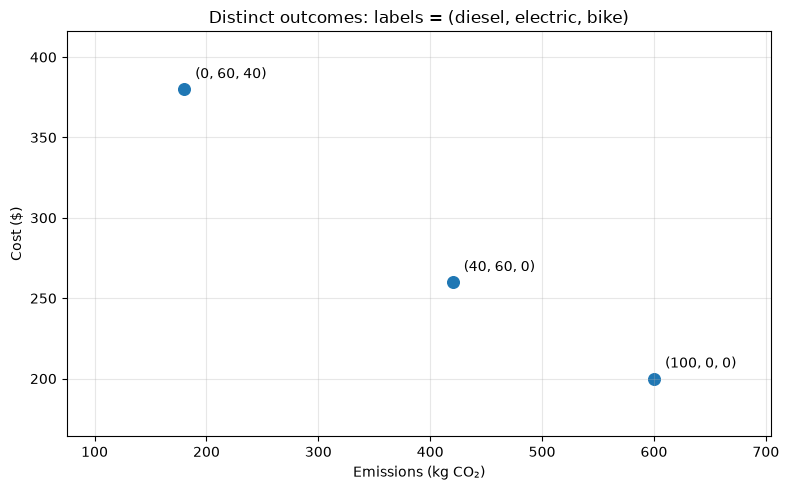

In [19]:
distinct = output.drop_duplicates(subset=["Cost", "Emissions"]).sort_values("Emissions")

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(distinct["Emissions"], distinct["Cost"], s=70)

for _, row in distinct.iterrows():
    label = (
        f"({int(row['Diesel'])}, " f"{int(row['Electric'])}, " f"{int(row['Bike'])})"
    )

    ax.annotate(
        label,
        (row["Emissions"], row["Cost"]),
        xytext=(8, 8),
        textcoords="offset points",
    )

ax.set_xlabel("Emissions (kg CO₂)")
ax.set_ylabel("Cost ($)")
ax.set_title("Distinct outcomes: labels = (diesel, electric, bike)")
ax.margins(x=0.25, y=0.20)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Explanation of results**

The eight runs produce three distinct delivery plans. Using only
diesel costs $200 and emits 600 kg CO₂. Using 40 diesel and 60 electric
deliveries costs $260 and emits 420 kg. Using 60 electric and 40 bike
deliveries costs $380 and emits 180 kg.

Electric capacity binds in the latter two plans. Bike capacity also
binds in the lowest-emission plan. All three emission-bound runs
reach their specified bounds.

Lambda is the dollar penalty assigned to each kg of CO₂. Increasing
it from 0.20 to 0.40 to 1.00 shifts the recommendation toward lower
emissions and higher delivery cost.

None of the reported outcomes is dominated: each reduction in
emissions comes with higher cost. GLPK certifies all solves as
globally optimal.